# 03 - Fairness Metrics (RQ1)

**Research question 1:** How unfair are Logistic Regression, Random Forest and XGBoost on Adult and COMPAS,
measured by demographic parity and equal opportunity?

| Metric | Definition | Perfectly fair value |
|---|---|---|
| Selection rate | share of a group predicted positive | - |
| Demographic parity (DP) difference | absolute gap in selection rate between the two groups | 0 |
| DP ratio | smaller selection rate / larger one (below 0.8 fails the "four-fifths rule") | 1 |
| Equal opportunity (EO) difference | absolute gap in true positive rate: among the truly positive, is each group found equally often? | 0 |
| Equalized odds difference | the larger of the TPR gap and the FPR gap | 0 |

*Positive prediction* means ">50K" for Adult and "will re-offend within two years" for COMPAS.
For COMPAS a positive prediction is **harmful** to the person, so a higher selection rate is the unfavourable side.

In [1]:
# --- Setup: works both in Google Colab and locally ---------------------------
# Colab: choose ONE way to get the project:
#   (a) USE_DRIVE = True  -> upload the fairness-xai folder to "My Drive"
#   (b) REPO_URL = "..."  -> clone it from GitHub
# Locally (Jupyter / VS Code) nothing needs changing.
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"
REPO_URL = ""  # e.g. "https://github.com/<your-user>/fairness-xai.git"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    elif REPO_URL:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        raise RuntimeError("Set USE_DRIVE = True or REPO_URL so Colab can find the project.")
    # Install the pinned versions once. If Colab then asks to "Restart session",
    # click it and run this cell again - the install is skipped the second time.
    try:
        already = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        already = False
    if not already:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
else:
    # Locally the notebook runs from notebooks/, so the project root is its parent.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


In [2]:
%matplotlib inline
import pandas as pd
from IPython.display import display

from src import config
from src.fairness import (plot_fairness_summary, plot_group_metrics, run_fairness,
                          save_fairness_tables)
from src.models import model_path, train_all
from src.preprocess import prepare_dataset

config.setup_logging()
pd.set_option("display.max_columns", 30)

## 1. Compute fairness for every dataset x setting x model x attribute
Models are loaded from `models/` (saved by notebook 02). If they are missing, they are trained here.

In [3]:
results = {}
for name in config.DATASETS:
    loaded, split = prepare_dataset(name, save=False)
    if all(model_path(name, s, m).exists() for s in config.SETTINGS for m in config.MODEL_NAMES):
        fitted = None  # run_fairness loads them from disk
    else:
        fitted = train_all(split, loaded.metadata)
    results[name] = (loaded.metadata, run_fairness(name, fitted=fitted, split=split, metadata=loaded.metadata))

summary = pd.concat([r[1][0] for r in results.values()], ignore_index=True)
by_group = pd.concat([r[1][1] for r in results.values()], ignore_index=True)
save_fairness_tables(summary, by_group)
print(f"{len(summary)} comparisons written to results/tables/fairness.csv")

21:33:47 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


21:33:47 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


21:33:51 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


21:33:54 | INFO    | src.fairness | Wrote fairness.csv (24 rows) and fairness_by_group.csv (48 rows).


24 comparisons written to results/tables/fairness.csv


In [4]:
cols = ["dataset", "setting", "model", "attribute", "privileged", "unprivileged",
        "selection_rate_privileged", "selection_rate_unprivileged",
        "dp_difference", "dp_ratio", "eo_difference", "eodds_difference"]
display(summary[cols].round(3))

,dataset,setting,model,attribute,privileged,unprivileged,selection_rate_privileged,selection_rate_unprivileged,dp_difference,dp_ratio,eo_difference,eodds_difference
0,adult,with_sensitive,logistic_regression,sex,Male,Female,0.259,0.078,0.180,0.303,0.124,0.124
1,adult,with_sensitive,logistic_regression,race,White,Non-White,0.212,0.124,0.088,0.583,0.062,0.062
2,adult,with_sensitive,random_forest,sex,Male,Female,0.247,0.072,0.176,0.289,0.132,0.132
3,adult,with_sensitive,random_forest,race,White,Non-White,0.202,0.115,0.087,0.568,0.062,0.062
4,adult,with_sensitive,xgboost,sex,Male,Female,0.270,0.089,0.181,0.330,0.080,0.080
5,adult,with_sensitive,xgboost,race,White,Non-White,0.223,0.132,0.091,0.592,0.050,0.050
6,adult,without_sensitive,logistic_regression,sex,Male,Female,0.255,0.082,0.173,0.323,0.096,0.096
7,adult,without_sensitive,logistic_regression,race,White,Non-White,0.210,0.131,0.079,0.622,0.034,0.034
8,adult,without_sensitive,random_forest,sex,Male,Female,0.248,0.072,0.176,0.291,0.131,0.131
9,adult,without_sensitive,random_forest,race,White,Non-White,0.202,0.122,0.080,0.605,0.034,0.034


## 2. Plain-English interpretation (with sensitive features)

In [5]:
for row in summary[summary["setting"] == "with_sensitive"].to_dict("records"):
    print("-", row["interpretation"])
    print("  ", row["interpretation_eo"])

- Logistic Regression predicts >50K for 26% of men but 8% of women (demographic parity difference 0.18).
   Among people who actually earn >50K, it correctly identifies 61% of men but only 48% of women (equal opportunity difference 0.12).
- Logistic Regression predicts >50K for 21% of White people but 12% of Non-White people (demographic parity difference 0.09).
   Among people who actually earn >50K, it correctly identifies 59% of White people but only 53% of Non-White people (equal opportunity difference 0.06).
- Random Forest predicts >50K for 25% of men but 7% of women (demographic parity difference 0.18).
   Among people who actually earn >50K, it correctly identifies 61% of men but only 48% of women (equal opportunity difference 0.13).
- Random Forest predicts >50K for 20% of White people but 11% of Non-White people (demographic parity difference 0.09).
   Among people who actually earn >50K, it correctly identifies 60% of White people but only 53% of Non-White people (equal oppo

## 3. Per-group charts
Blue = privileged group, orange = unprivileged group. Each panel is one metric; each pair of bars is one model.

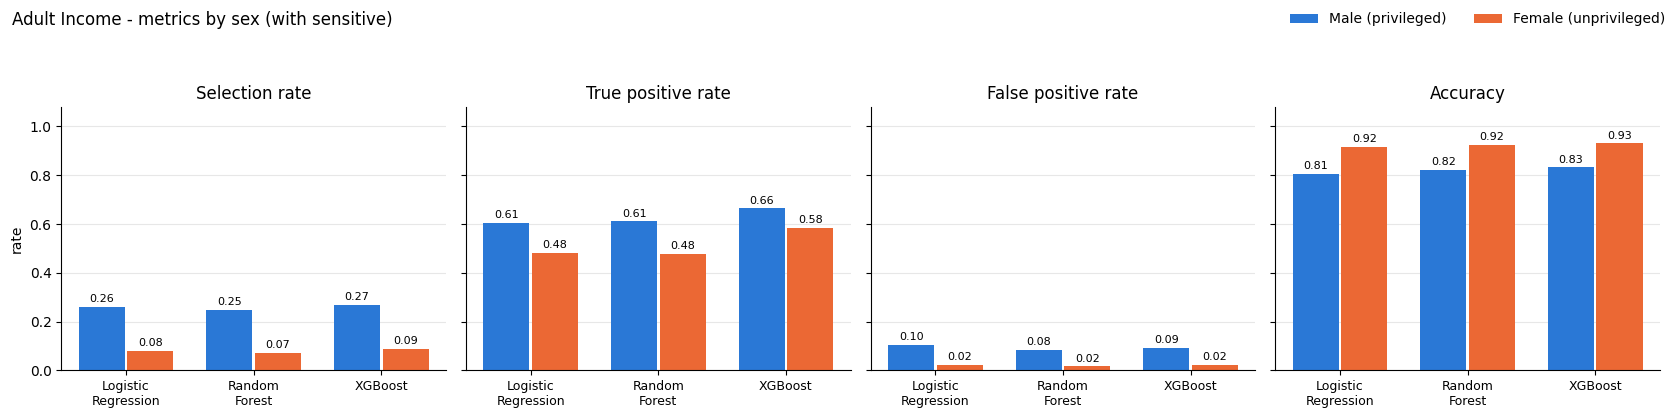

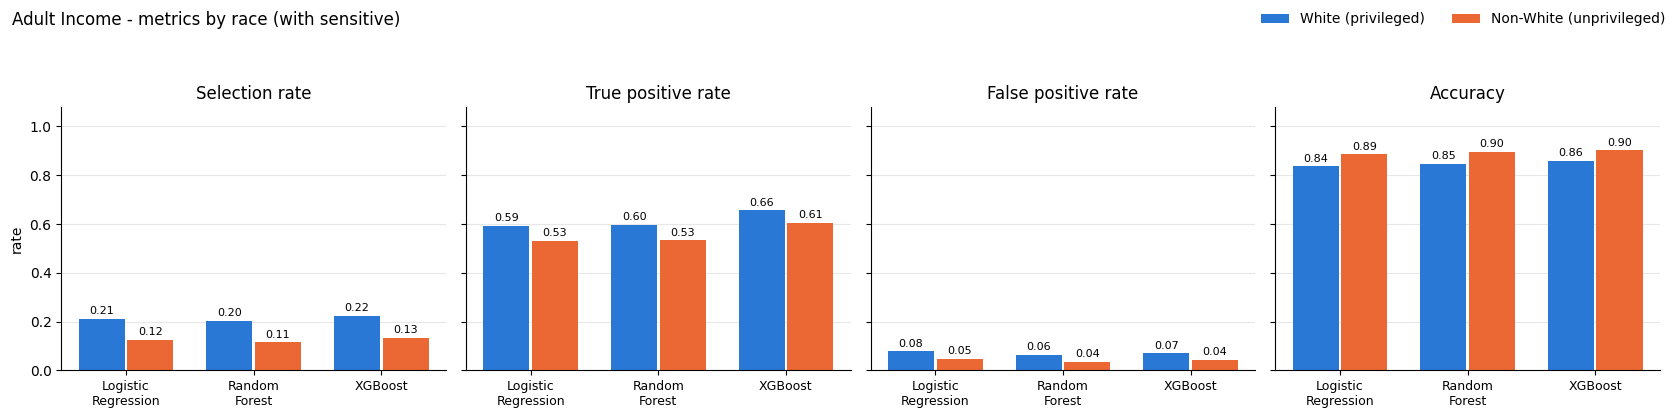

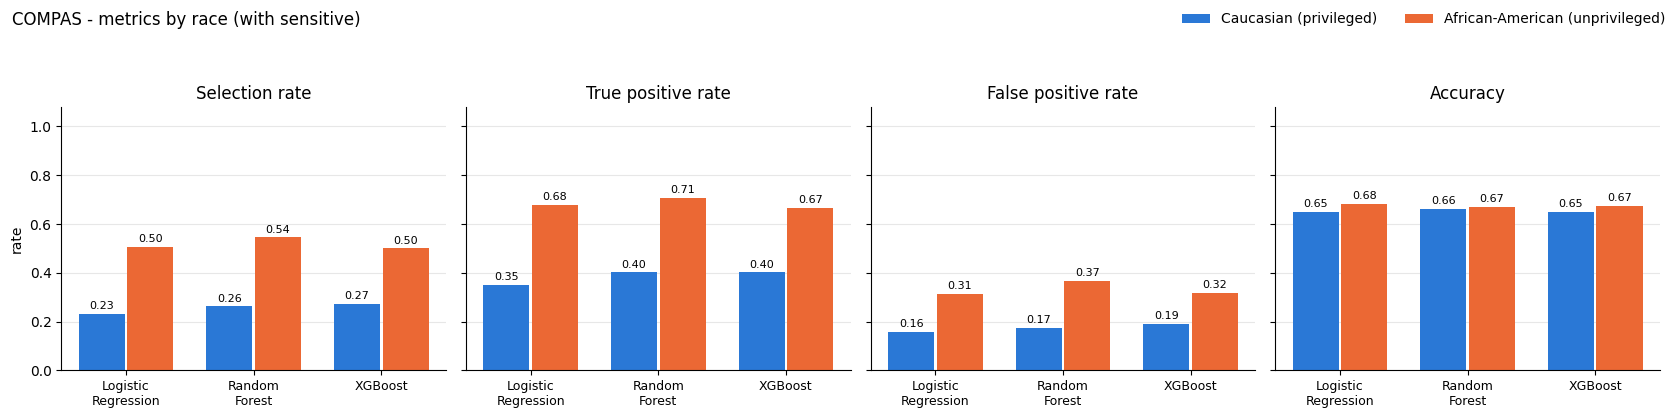

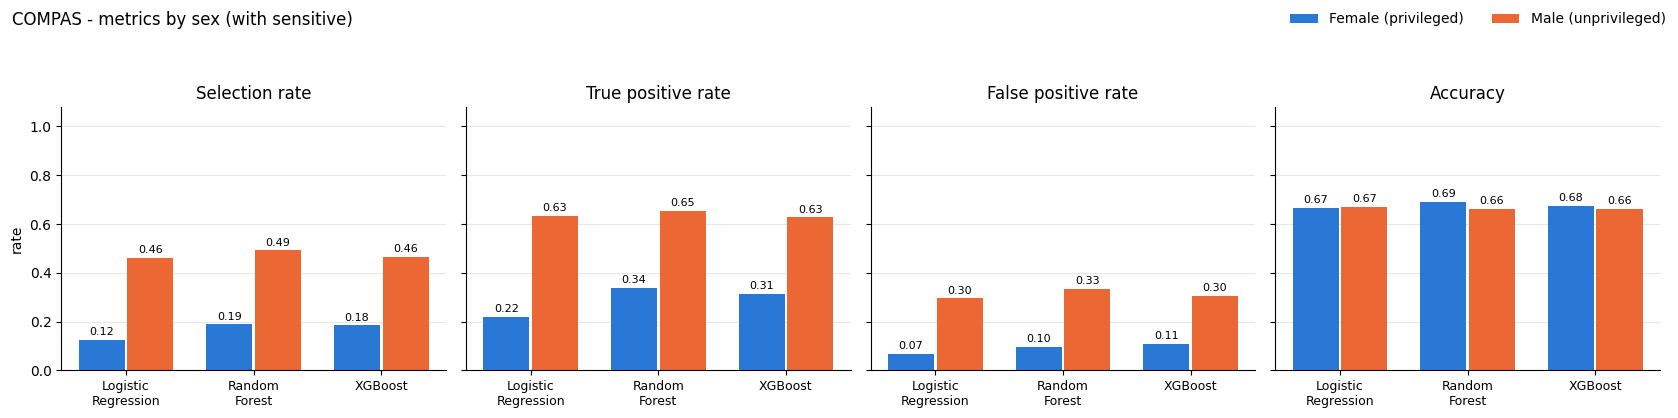

In [6]:
for name, (metadata, _) in results.items():
    for attribute in metadata.sensitive_attributes:
        display(plot_group_metrics(by_group, metadata, "with_sensitive", attribute))

## 4. Does the model copy, narrow or amplify the gap in the data?
The **base-rate difference** is the gap in *real* outcomes between the groups (test set). If the model's DP
difference is larger than the base-rate difference, the model **amplifies** the disparity already in the data.

In [7]:
amp = summary[summary["setting"] == "with_sensitive"][
    ["dataset", "model", "attribute", "base_rate_difference", "dp_difference"]].copy()
amp["dp_minus_base_gap"] = amp["dp_difference"] - amp["base_rate_difference"]
amp["effect"] = amp["dp_minus_base_gap"].map(
    lambda d: "amplifies" if d > 0.01 else ("narrows" if d < -0.01 else "copies"))
display(amp.round(3))

,dataset,model,attribute,base_rate_difference,dp_difference,dp_minus_base_gap,effect
0,adult,logistic_regression,sex,0.190,0.180,-0.010,narrows
1,adult,logistic_regression,race,0.103,0.088,-0.015,narrows
2,adult,random_forest,sex,0.190,0.176,-0.015,narrows
3,adult,random_forest,race,0.103,0.087,-0.016,narrows
4,adult,xgboost,sex,0.190,0.181,-0.010,copies
5,adult,xgboost,race,0.103,0.091,-0.012,narrows
12,compas,logistic_regression,race,0.133,0.272,0.140,amplifies
13,compas,logistic_regression,sex,0.118,0.338,0.220,amplifies
14,compas,random_forest,race,0.133,0.283,0.150,amplifies
15,compas,random_forest,sex,0.118,0.303,0.186,amplifies


## 5. Fairness through unawareness: does removing the sensitive feature help?
Each bar pair compares the same model trained with (dark) and without (light) the sensitive features.
If the light bar is still far from zero, **other features (proxies) still carry the group information**.

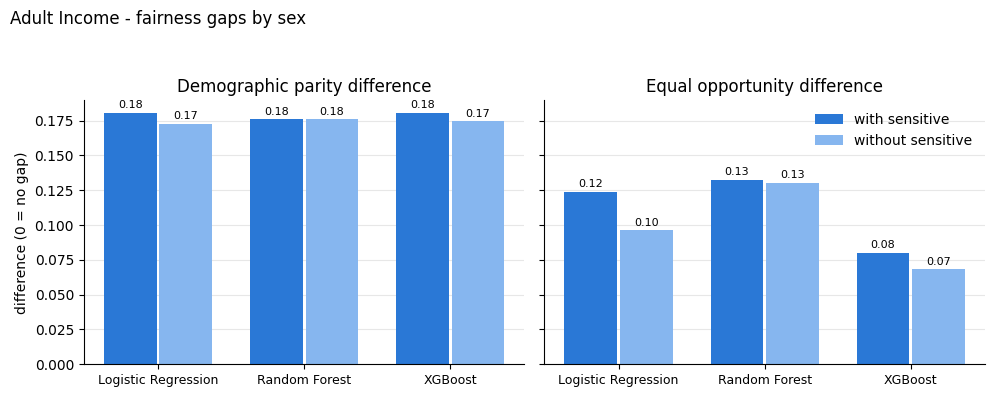

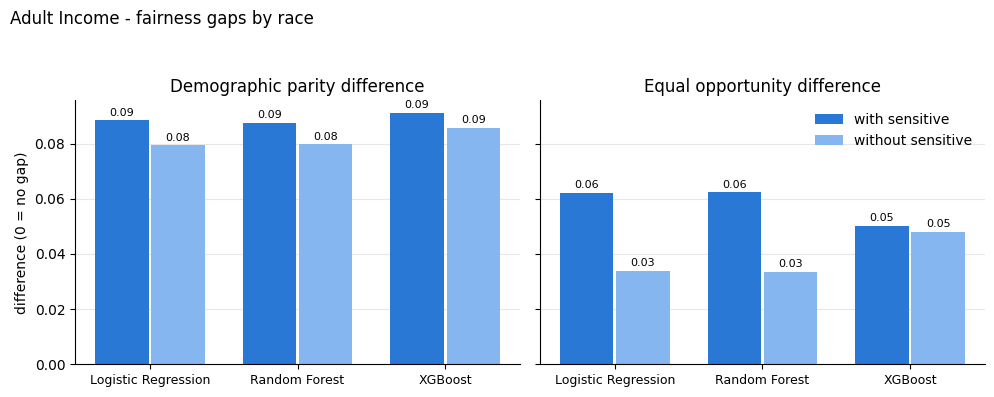

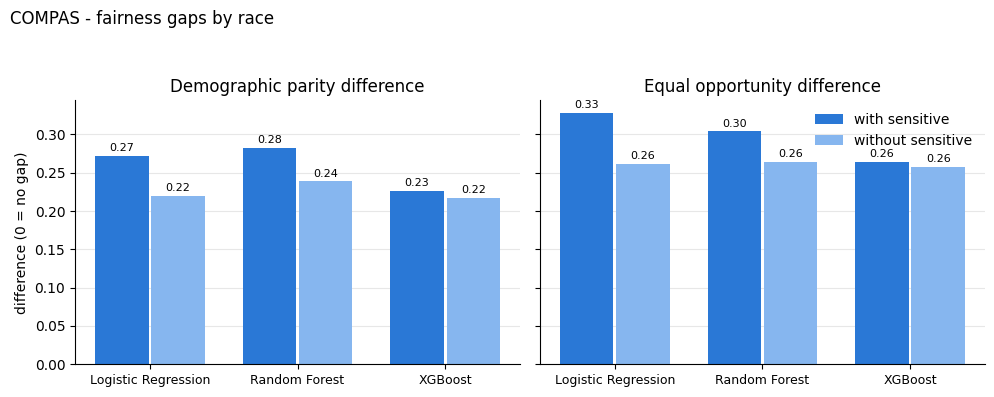

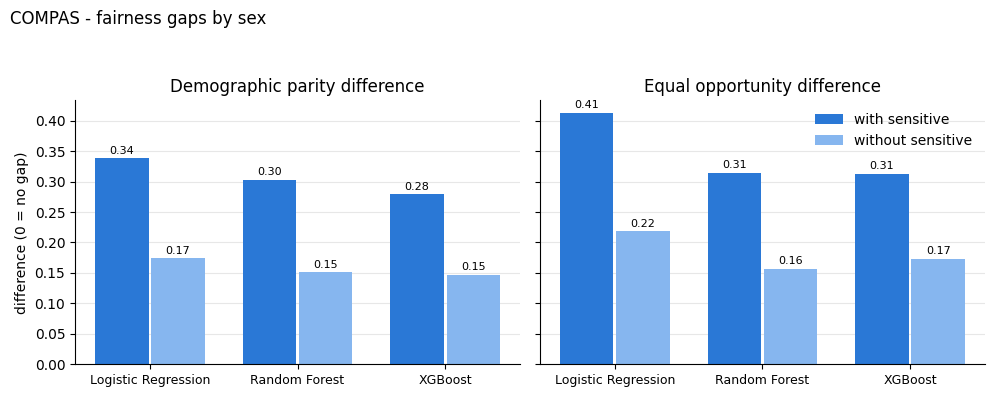

In [8]:
for name, (metadata, _) in results.items():
    for attribute in metadata.sensitive_attributes:
        display(plot_fairness_summary(summary, name, attribute))

In [9]:
wide = summary.pivot_table(index=["dataset", "attribute", "model"], columns="setting",
                           values=["dp_difference", "eo_difference"])
change = pd.DataFrame({
    "dp_with": wide[("dp_difference", "with_sensitive")],
    "dp_without": wide[("dp_difference", "without_sensitive")],
    "eo_with": wide[("eo_difference", "with_sensitive")],
    "eo_without": wide[("eo_difference", "without_sensitive")],
})
change["dp_share_removed"] = 1 - change["dp_without"] / change["dp_with"]
display(change.round(3))
for (dataset, attribute), part in change.groupby(level=[0, 1]):
    print(f"{config.DATASET_DISPLAY_NAMES[dataset]}, {attribute}: removing the sensitive features removes on average "
          f"{part['dp_share_removed'].mean():.0%} of the demographic parity gap "
          f"(remaining DP difference {part['dp_without'].min():.2f}-{part['dp_without'].max():.2f}).")

dp_with  dp_without  eo_with  \
dataset attribute model                                               
adult   race      logistic_regression    0.088       0.079    0.062   
                  random_forest          0.087       0.080    0.062   
                  xgboost                0.091       0.086    0.050   
        sex       logistic_regression    0.180       0.173    0.124   
                  random_forest          0.176       0.176    0.132   
                  xgboost                0.181       0.174    0.080   
compas  race      logistic_regression    0.272       0.220    0.328   
                  random_forest          0.283       0.239    0.304   
                  xgboost                0.226       0.217    0.264   
        sex       logistic_regression    0.338       0.174    0.413   
                  random_forest          0.303       0.151    0.315   
                  xgboost                0.279       0.147    0.313   

                                       eo_without  dp_share_removed  
dataset attribute model                                              
adult   race      logistic_regression       0.034             0.103  
                  random_forest             0.034             0.088  
                  xgboost                   0.048             0.059  
        sex       logistic_regression       0.096             0.041  
                  random_forest             0.131            -0.001  
                  xgboost                   0.068             0.034  
compas  race      logistic_regression       0.262             0.192  
                  random_forest             0.264             0.156  
                  xgboost                   0.258             0.040  
        sex       logistic_regression       0.218             0.486  
                  random_forest             0.156             0.502  
                  xgboost                   0.173             0.472

Adult Income, race: removing the sensitive features removes on average 8% of the demographic parity gap (remaining DP difference 0.08-0.09).
Adult Income, sex: removing the sensitive features removes on average 2% of the demographic parity gap (remaining DP difference 0.17-0.18).
COMPAS, race: removing the sensitive features removes on average 13% of the demographic parity gap (remaining DP difference 0.22-0.24).
COMPAS, sex: removing the sensitive features removes on average 49% of the demographic parity gap (remaining DP difference 0.15-0.17).


## 6. Four-fifths rule check

In [10]:
fails = summary[summary["dp_ratio"] < 0.8]
print(f"{len(fails)} of {len(summary)} model/attribute/setting combinations have a DP ratio below 0.8.")
print(f"Lowest DP ratio: {summary['dp_ratio'].min():.2f}; highest: {summary['dp_ratio'].max():.2f}.")

24 of 24 model/attribute/setting combinations have a DP ratio below 0.8.
Lowest DP ratio: 0.27; highest: 0.67.


## Summary (answer to RQ1)
The printed findings above answer RQ1 with numbers from this run:
* the plain-English sentences give each model's selection rates per group;
* section 4 shows where models **amplify** the gap already present in the data;
* section 5 shows how much of the gap survives when the sensitive features are removed - the part that survives
  must be coming through other features, which Phase 4 identifies as **proxies**;
* section 6 checks the four-fifths rule.

Next: `04_explanations_compare.ipynb` - do the *explanations* treat the groups differently (RQ2, RQ3)?